<a href="https://colab.research.google.com/github/Chathuranga630/sionna/blob/main/spoofed_traffic_v4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install sionna

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 687.1/687.1 kB 31.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 66.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 44.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 54.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.5/8.5 MB 50.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 40.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.6/62.6 MB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.1/140.1 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 50.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 271.7/271.7 kB 13.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 39.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 37.5

In [ ]:
pip show sionna


Name: sionna
Version: 2.2.0
Summary: Sionna - A hardware-accelerated differentiable open-source library for research on communication systems
Home-page: 
Author: 
Author-email: The Sionna contributors <sionna@nvidia.com>
License: Apache-2.0
Location: /usr/local/lib/python3.13/dist-packages
Requires: h5py, importlib-resources, matplotlib, numpy, scipy, sionna-rt, torch
Required-by: 


In [ ]:
# STEP 1 — Import libraries and initialize reproducibility
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import sionna

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("NumPy:", np.__version__)
print("TensorFlow:", tf.__version__)
print("Sionna:", sionna.__version__)

NumPy: 2.5.4
TensorFlow: 2.21.0
Sionna: 2.2.0


In [ ]:
# STEP 2 — Define the simulation area
import numpy as np
import matplotlib.pyplot as plt

# Simulation area (meters)
AREA_X = 1000
AREA_Y = 1000

print("Simulation Area:", AREA_X, "x", AREA_Y, "meters")

Simulation Area: 1000 x 1000 meters


In [ ]:
# Step 3 — Base-station positions
bs_positions = np.array([
    [250,250],
    [750,250],
    [500,750]
])

print(bs_positions)

[[250 250]
 [750 250]
 [500 750]]


In [ ]:
# Step 4 — Fixed user positions
num_users = 30

user_positions = np.random.rand(num_users,2)

user_positions[:,0] *= AREA_X
user_positions[:,1] *= AREA_Y

print(user_positions)

[[374.54011885 950.71430641]
 [731.99394181 598.6584842 ]
 [156.01864044 155.99452034]
 [ 58.08361217 866.17614577]
 [601.11501174 708.0725778 ]
 [ 20.5844943  969.90985216]
 [832.4426408  212.33911068]
 [181.82496721 183.40450985]
 [304.24224296 524.75643163]
 [431.94501864 291.2291402 ]
 [611.85289472 139.49386065]
 [292.14464854 366.36184329]
 [456.06998422 785.17596139]
 [199.67378216 514.23443841]
 [592.41456886  46.45041272]
 [607.5448519  170.52412369]
 [ 65.05159299 948.88553725]
 [965.63203307 808.39734812]
 [304.61376917  97.67211401]
 [684.23302651 440.15249374]
 [122.03823484 495.17691011]
 [ 34.38852112 909.32040208]
 [258.7799816  662.52228435]
 [311.71107609 520.06802118]
 [546.71027934 184.85445553]
 [969.58462776 775.13282336]
 [939.49894156 894.82735043]
 [597.89997881 921.87423502]
 [ 88.49250205 195.98286242]
 [ 45.22728891 325.33033076]]


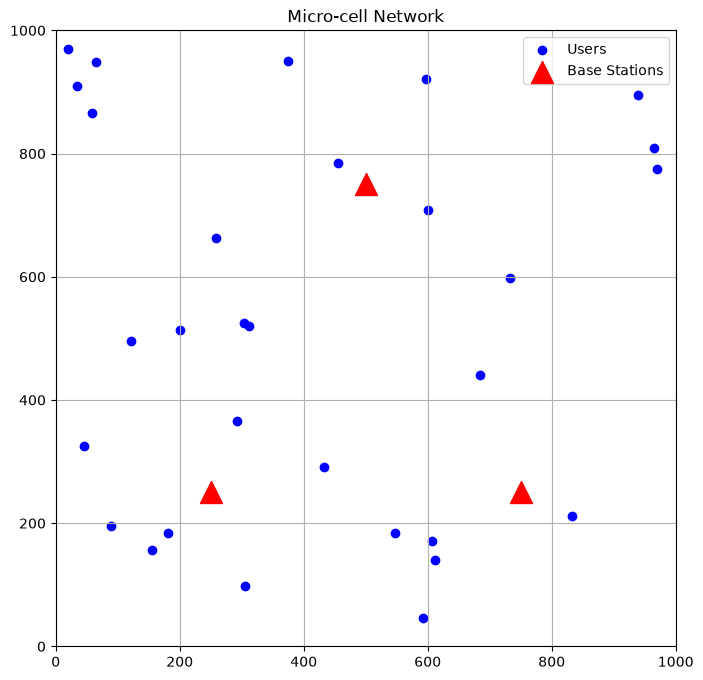

In [ ]:
# Step 5 — Plot the network layout
plt.figure(figsize=(8,8))

# Users
plt.scatter(
    user_positions[:,0],
    user_positions[:,1],
    c='blue',
    label='Users'
)

# Base Stations
plt.scatter(
    bs_positions[:,0],
    bs_positions[:,1],
    c='red',
    s=250,
    marker='^',
    label='Base Stations'
)

plt.xlim(0,AREA_X)
plt.ylim(0,AREA_Y)

plt.grid(True)
plt.legend()

plt.title("Micro-cell Network")

plt.savefig("step5_figures_network_layout_1.png", dpi=300, bbox_inches="tight")
plt.show()


In [ ]:
# Step 6 — Calculate BS–UE distances
import tensorflow as tf
import sionna
import numpy as np
import matplotlib.pyplot as plt


# Distance matrix
distance_matrix = np.zeros((len(user_positions), len(bs_positions)))

for i, user in enumerate(user_positions):

    for j, bs in enumerate(bs_positions):

        distance = np.linalg.norm(user-bs)

        distance_matrix[i,j] = distance

print(distance_matrix)

[[ 711.69570774  794.96582415  236.69899572]
 [ 594.87889402  349.12312546  276.99358015]
 [ 132.92676988  601.37416448  686.41509715]
 [ 645.37194124  926.51029696  456.93215107]
 [ 577.15876325  481.66090381  109.46302724]
 [ 755.58035277 1024.84983056  527.44627232]
 [ 583.65895213   90.63736319  632.13712225]
 [  95.30369565  572.06453062  649.81982191]
 [ 280.05948947  523.63257603  298.42212474]
 [ 186.55785111  320.71609434  463.79109768]
 [ 378.35053093  176.90740383  620.66804029]
 [ 123.75883797  472.41041631  436.32795282]
 [ 573.47898658  610.58018624   56.27783353]
 [ 268.98432416  610.47422918  381.81309191]
 [ 398.34679797  257.42106089  709.59317521]
 [ 366.27139669  163.12536325  589.37100913]
 [ 722.9432256   978.56799174  478.26308   ]
 [ 907.70964804  598.58564305  469.2797039 ]
 [ 161.82227484  470.71507248  680.96068171]
 [ 474.0425004   201.20453692  360.48201785]
 [ 276.56089853  674.1273587   455.83977784]
 [ 693.67982703  973.03811914  492.11486442]
 [ 412.615

In [ ]:
assignments = np.argmin(distance_matrix, axis=1)

print(assignments)

[2 2 0 2 2 2 1 0 0 0 1 0 2 0 1 1 2 2 0 1 0 2 2 0 1 2 2 2 0 0]


In [ ]:
for bs in range(len(bs_positions)):

    count = np.sum(assignments==bs)

    print(f"BS {bs+1} has {count} users")

BS 1 has 11 users
BS 2 has 6 users
BS 3 has 13 users


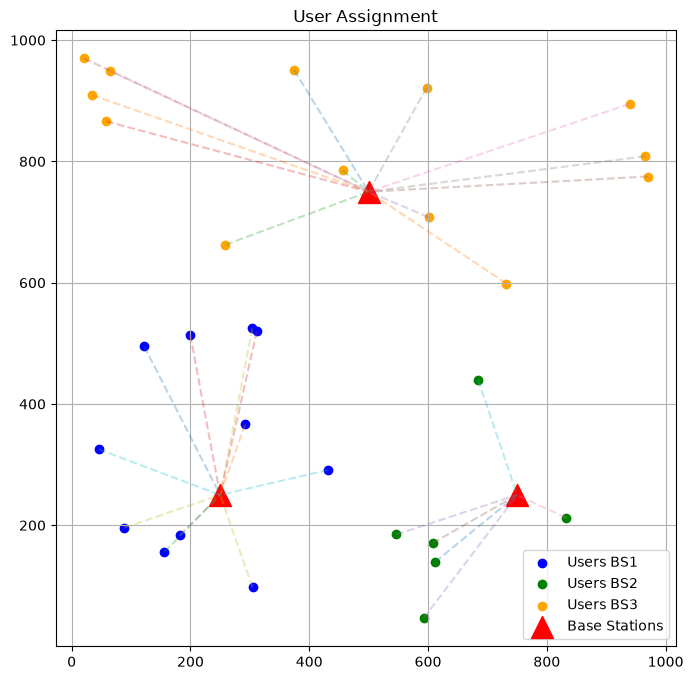

In [ ]:
plt.figure(figsize=(8,8))

colors=['blue','green','orange']

# Draw users

for bs in range(3):

    idx = assignments==bs

    plt.scatter(
        user_positions[idx,0],
        user_positions[idx,1],
        color=colors[bs],
        label=f'Users BS{bs+1}'
    )

# Draw Base Stations

plt.scatter(
    bs_positions[:,0],
    bs_positions[:,1],
    marker='^',
    color='red',
    s=250,
    label='Base Stations'
)

# Draw association lines

for i,user in enumerate(user_positions):

    bs=assignments[i]

    plt.plot(
        [user[0],bs_positions[bs][0]],
        [user[1],bs_positions[bs][1]],
        '--',
        alpha=0.3
    )

plt.grid()

plt.legend()

plt.title("User Assignment")

plt.savefig("step6_figures_network_layout_2.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
import pandas as pd

results = pd.DataFrame({
    "User": range(1, len(assignments)+1),
    "Assigned_BS": assignments
})

results.to_csv("user_assignment.csv", index=False)

In [ ]:
# -------------------------------
# Step 7 Network Parameters
# -------------------------------

frequency = 3500      # MHz (5G frequency)
tx_power = 30         # dBm (micro-cell transmit power)

print("Frequency:", frequency, "MHz")
print("Transmit Power:", tx_power, "dBm")

Frequency: 3500 MHz
Transmit Power: 30 dBm


In [ ]:
distance_matrix
print(distance_matrix)

[[ 711.69570774  794.96582415  236.69899572]
 [ 594.87889402  349.12312546  276.99358015]
 [ 132.92676988  601.37416448  686.41509715]
 [ 645.37194124  926.51029696  456.93215107]
 [ 577.15876325  481.66090381  109.46302724]
 [ 755.58035277 1024.84983056  527.44627232]
 [ 583.65895213   90.63736319  632.13712225]
 [  95.30369565  572.06453062  649.81982191]
 [ 280.05948947  523.63257603  298.42212474]
 [ 186.55785111  320.71609434  463.79109768]
 [ 378.35053093  176.90740383  620.66804029]
 [ 123.75883797  472.41041631  436.32795282]
 [ 573.47898658  610.58018624   56.27783353]
 [ 268.98432416  610.47422918  381.81309191]
 [ 398.34679797  257.42106089  709.59317521]
 [ 366.27139669  163.12536325  589.37100913]
 [ 722.9432256   978.56799174  478.26308   ]
 [ 907.70964804  598.58564305  469.2797039 ]
 [ 161.82227484  470.71507248  680.96068171]
 [ 474.0425004   201.20453692  360.48201785]
 [ 276.56089853  674.1273587   455.83977784]
 [ 693.67982703  973.03811914  492.11486442]
 [ 412.615

In [ ]:
# Step 8 — Path loss
distance_km = distance_matrix / 1000

# Avoid log10(0)
distance_km[distance_km < 0.001] = 0.001

import numpy as np

path_loss = 32.44 \
            + 20*np.log10(frequency) \
            + 20*np.log10(distance_km)

print(path_loss)

[[100.36724782 101.32833006  90.80528919]
 [ 98.8099321   94.18093322  92.17075496]
 [ 85.79360992  98.90425622 100.05309743]
 [ 99.51756248 102.65836589  96.51839523]
 [ 98.54726677  96.97618881  84.10670998]
 [100.88697402 103.53456556  97.76492543]
 [ 98.64454391  82.46750614  99.33758679]
 [ 82.90355572  98.47026131  99.57721998]
 [ 92.26636674  97.70189402  92.81798125]
 [ 88.7376315   93.44377598  96.64780905]
 [ 94.87924784  88.27628107  99.17854855]
 [ 85.17288535  96.80775019  96.11762162]
 [ 98.49171107  99.03621503  78.3281083 ]
 [ 91.91590031  99.03470759  94.9583772 ]
 [ 95.3265875   91.5342424  100.34154948]
 [ 94.59742098  87.57179072  98.72913627]
 [100.50344474 103.13318101  96.91469801]
 [102.48029992  98.86388681  96.74999632]
 [ 87.50212693  96.77652298  99.98380162]
 [ 96.83770649  89.39411627  94.459033  ]
 [ 92.15717644  99.89619994  96.49760529]
 [100.14454219 103.08395797  97.16269055]
 [ 95.63227605  99.46476103  91.5062227 ]
 [ 92.17186139  97.55437544  92.78

In [ ]:
# Step 9 — Received power
received_power = tx_power - path_loss

print(received_power)

[[-70.36724782 -71.32833006 -60.80528919]
 [-68.8099321  -64.18093322 -62.17075496]
 [-55.79360992 -68.90425622 -70.05309743]
 [-69.51756248 -72.65836589 -66.51839523]
 [-68.54726677 -66.97618881 -54.10670998]
 [-70.88697402 -73.53456556 -67.76492543]
 [-68.64454391 -52.46750614 -69.33758679]
 [-52.90355572 -68.47026131 -69.57721998]
 [-62.26636674 -67.70189402 -62.81798125]
 [-58.7376315  -63.44377598 -66.64780905]
 [-64.87924784 -58.27628107 -69.17854855]
 [-55.17288535 -66.80775019 -66.11762162]
 [-68.49171107 -69.03621503 -48.3281083 ]
 [-61.91590031 -69.03470759 -64.9583772 ]
 [-65.3265875  -61.5342424  -70.34154948]
 [-64.59742098 -57.57179072 -68.72913627]
 [-70.50344474 -73.13318101 -66.91469801]
 [-72.48029992 -68.86388681 -66.74999632]
 [-57.50212693 -66.77652298 -69.98380162]
 [-66.83770649 -59.39411627 -64.459033  ]
 [-62.15717644 -69.89619994 -66.49760529]
 [-70.14454219 -73.08395797 -67.16269055]
 [-65.63227605 -69.46476103 -61.5062227 ]
 [-62.17186139 -67.55437544 -62.78

In [ ]:
assignments_signal = np.argmax(received_power, axis=1)

print(assignments_signal)


[2 2 0 2 2 2 1 0 0 0 1 0 2 0 1 1 2 2 0 1 0 2 2 0 1 2 2 2 0 0]


In [ ]:
for bs in range(len(bs_positions)):

    count = np.sum(assignments_signal == bs)

    print(f"BS {bs+1}: {count} users")

BS 1: 11 users
BS 2: 6 users
BS 3: 13 users


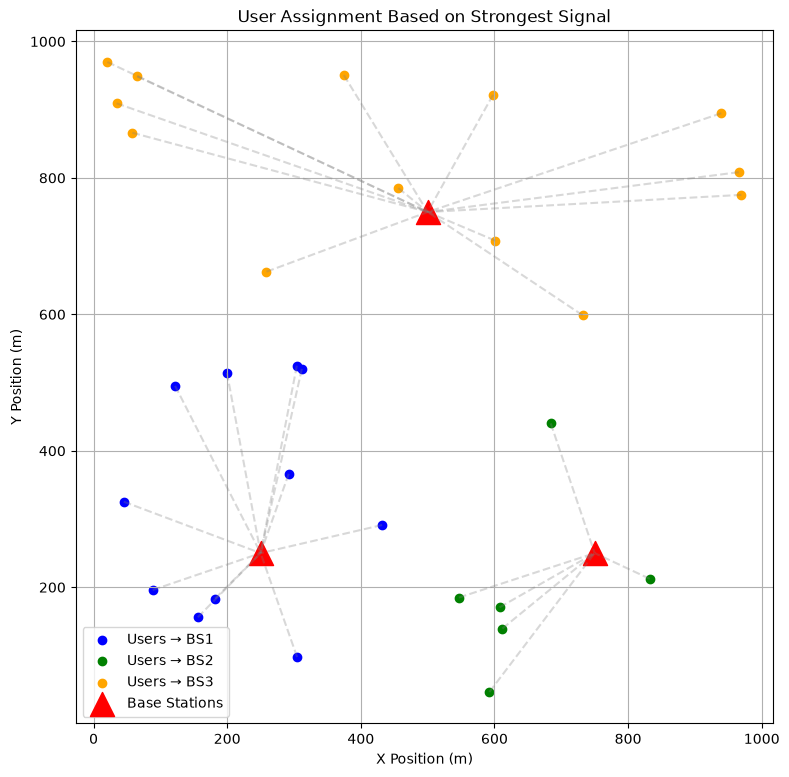

In [ ]:
plt.figure(figsize=(9,9))

colors = ['blue','green','orange']

for bs in range(3):

    idx = assignments_signal == bs

    plt.scatter(
        user_positions[idx,0],
        user_positions[idx,1],
        color=colors[bs],
        label=f'Users → BS{bs+1}'
    )

plt.scatter(
    bs_positions[:,0],
    bs_positions[:,1],
    marker='^',
    s=300,
    color='red',
    label='Base Stations'
)

# Draw association lines

for i,user in enumerate(user_positions):

    bs = assignments_signal[i]

    plt.plot(
        [user[0],bs_positions[bs][0]],
        [user[1],bs_positions[bs][1]],
        '--',
        alpha=0.3,
        color='gray'
    )

plt.title("User Assignment Based on Strongest Signal")

plt.xlabel("X Position (m)")
plt.ylabel("Y Position (m)")

plt.grid(True)

plt.legend()

plt.savefig("step9_figures_user_assignment_signal_3.png",
            dpi=300,
            bbox_inches="tight")

plt.show()

In [ ]:
import pandas as pd

results = pd.DataFrame({
    "User": np.arange(1, len(user_positions)+1),
    "Assigned_BS": assignments_signal + 1,
    "Best_RSRP_dBm": np.max(received_power, axis=1)
})

print(results.head())

results.to_csv("step9_user_assignment.csv", index=False)

   User  Assigned_BS  Best_RSRP_dBm
0     1            3     -60.805289
1     2            3     -62.170755
2     3            1     -55.793610
3     4            3     -66.518395
4     5            3     -54.106710


In [ ]:
# ======================================================
# STEP 10 - Sionna PHY Integration
# Small-Scale Fading
# ======================================================

import tensorflow as tf
import numpy as np

np.random.seed(42)
tf.random.set_seed(42)

num_users = len(user_positions)

In [ ]:
# Rayleigh fading coefficient

# Real part
real = tf.random.normal([num_users], dtype=tf.float32)

# Imaginary part
imag = tf.random.normal([num_users], dtype=tf.float32)

# Create complex channel coefficients
h = tf.complex(real, imag) / tf.cast(tf.sqrt(2.0), tf.complex64)

print(h[:10])

tf.Tensor(
[ 0.23155521+5.9555773e-02j -0.59582645-6.0875088e-01j
  0.22587374+2.6737338e-01j -0.9952895 -3.6743204e-03j
 -1.6886133 -3.4968692e-01j -0.7348592 +4.3686414e-01j
 -0.39408705-2.3392540e-01j  0.38163048-9.7869278e-04j
  1.2016801 -2.9962525e-01j  0.204309  -9.8090470e-01j], shape=(10,), dtype=complex64)


In [ ]:
# Channel Power Gain
channel_gain = tf.abs(h)**2

channel_gain = channel_gain.numpy()

print(channel_gain[:10])

[0.0571647  0.7255867  0.12250747 0.9906146  2.973696   0.7308683
 0.2100257  0.14564276 1.5338105  1.003916  ]


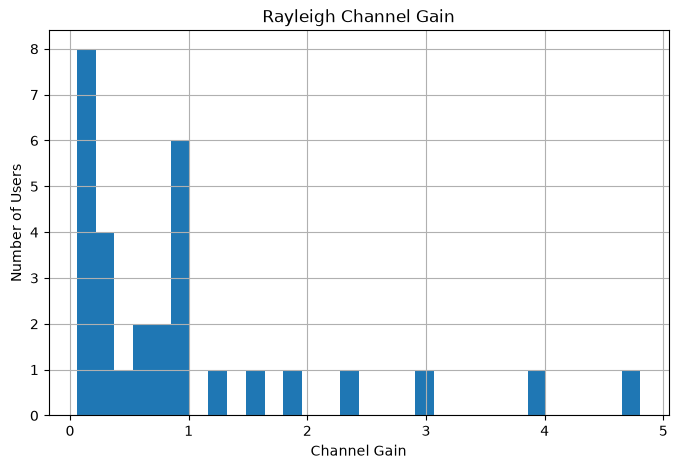

In [ ]:
# Plot the Fading Distribution
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.hist(channel_gain,
         bins=30)

plt.xlabel("Channel Gain")

plt.ylabel("Number of Users")

plt.title("Rayleigh Channel Gain")

plt.grid(True)

plt.savefig(
    "figures_step10_channel_gain.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
received_power
channel_gain = channel_gain.reshape(-1, 1)

received_power_fading = received_power + 10*np.log10(channel_gain)

print(received_power_fading[:10])

[[-82.79596925 -83.75705149 -73.23401062]
 [-70.20303904 -65.57404016 -63.5638619 ]
 [-64.91198474 -78.02263104 -79.17147225]
 [-69.55851527 -72.69931868 -66.55934802]
 [-63.81430082 -62.24322287 -49.37374403]
 [-72.248583   -74.89617454 -69.12653442]
 [-75.42181995 -59.24478218 -76.11486283]
 [-61.27066693 -76.83737252 -77.94433119]
 [-60.40864959 -65.84417687 -60.96026409]
 [-58.72065763 -63.42680211 -66.63083518]]


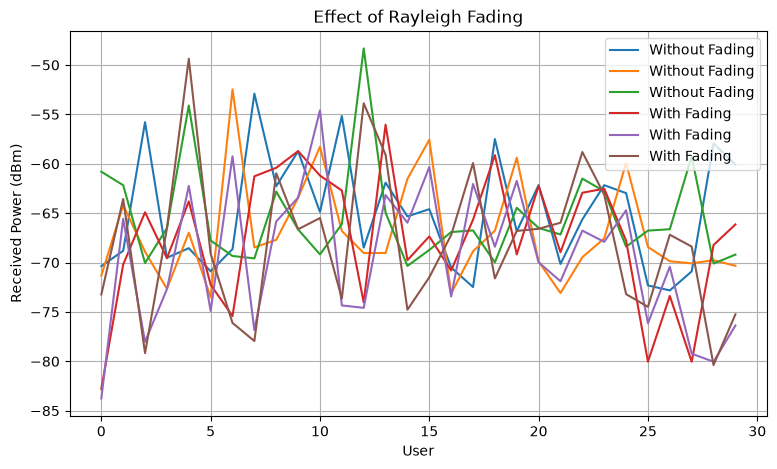

In [ ]:
# Plot the Difference
plt.figure(figsize=(9,5))

plt.plot(received_power,
         label="Without Fading")

plt.plot(received_power_fading,
         label="With Fading")

plt.xlabel("User")

plt.ylabel("Received Power (dBm)")

plt.title("Effect of Rayleigh Fading")

plt.legend()

plt.grid(True)

plt.savefig(
    "figures_step10_received_power_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# Recalculate SINR
received_power_mW = 10**(received_power_fading/10)

noise_power = 1e-10

sinr = received_power_mW / noise_power

sinr_dB = 10*np.log10(sinr)

print(sinr_dB[:10])

[[17.20403075 16.24294851 26.76598938]
 [29.79696096 34.42595984 36.4361381 ]
 [35.08801526 21.97736896 20.82852775]
 [30.44148473 27.30068132 33.44065198]
 [36.18569918 37.75677713 50.62625597]
 [27.751417   25.10382546 30.87346558]
 [24.57818005 40.75521782 23.88513717]
 [38.72933307 23.16262748 22.05566881]
 [39.59135041 34.15582313 39.03973591]
 [41.27934237 36.57319789 33.36916482]]


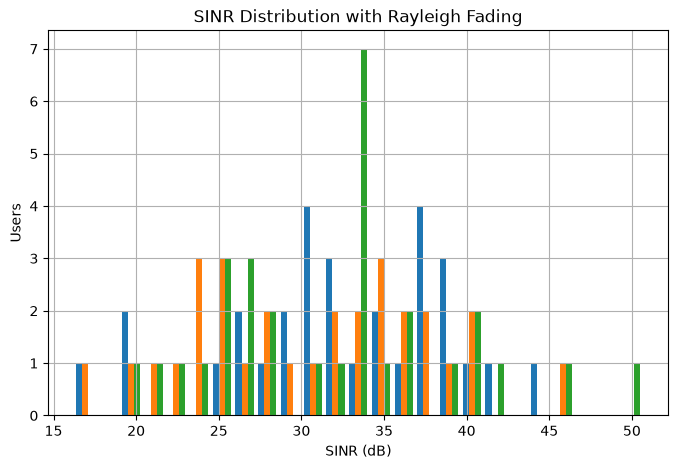

In [ ]:
# Compare SINR
plt.figure(figsize=(8,5))

plt.hist(sinr_dB,
         bins=25)

plt.xlabel("SINR (dB)")

plt.ylabel("Users")

plt.title("SINR Distribution with Rayleigh Fading")

plt.grid(True)

plt.savefig(
    "figures_step10_sinr_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# =====================================================
# STEP 11 - Beamforming
# =====================================================

beamforming_gain_dB = 6

print("Beamforming Gain:", beamforming_gain_dB, "dB")

received_power_beamforming = received_power_fading + beamforming_gain_dB

print(received_power_beamforming[:5])
print(received_power_fading.shape)

Beamforming Gain: 6 dB
[[-76.79596925 -77.75705149 -67.23401062]
 [-64.20303904 -59.57404016 -57.5638619 ]
 [-58.91198474 -72.02263104 -73.17147225]
 [-63.55851527 -66.69931868 -60.55934802]
 [-57.81430082 -56.24322287 -43.37374403]]
(30, 3)


In [ ]:
# Calculate New SINR
received_power_mW = 10 ** (received_power_beamforming / 10)
# Assume:
noise_power_mW = 1e-10

sinr_beam = received_power_mW / noise_power_mW

sinr_beam_dB = 10 * np.log10(sinr_beam)

In [ ]:
# Compare Average SINR
print("Average SINR without Beamforming:")

print(np.mean(sinr_dB))

print()

print("Average SINR with Beamforming:")

print(np.mean(sinr_beam_dB))

Average SINR without Beamforming:
31.643002657857146

Average SINR with Beamforming:
37.643002657857146


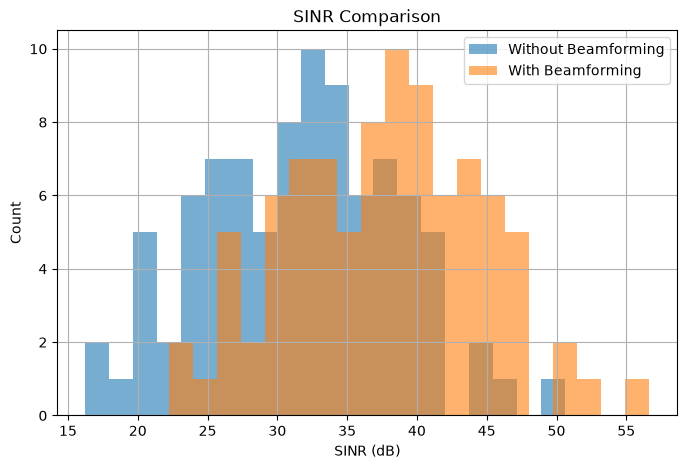

In [ ]:
# Plot the Comparison
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.hist(
    sinr_dB.flatten(),
    bins=20,
    alpha=0.6,
    label="Without Beamforming"
)

plt.hist(
    sinr_beam_dB.flatten(),
    bins=20,
    alpha=0.6,
    label="With Beamforming"
)

plt.xlabel("SINR (dB)")
plt.ylabel("Count")
plt.title("SINR Comparison")

plt.legend()
plt.grid(True)

plt.savefig(
    "figures_step11_sinr_beamforming.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
import numpy as np

# Check the shape first
print("Received power shape:", received_power_beamforming.shape)

# Assign each user to the BS with the highest received power
assignments_beamforming = np.argmax(
    received_power_beamforming,
    axis=1
)

print("User assignments:")
print(assignments_beamforming)

Received power shape: (30, 3)
User assignments:
[2 2 0 2 2 2 1 0 0 0 1 0 2 0 1 1 2 2 0 1 0 2 2 0 1 2 2 2 0 0]


In [ ]:
# Count Users Per Base Station
num_bs = received_power_beamforming.shape[1]

users_per_bs = np.bincount(
    assignments_beamforming,
    minlength=num_bs
)

for bs in range(num_bs):
    print(f"BS {bs+1}: {users_per_bs[bs]} users")

BS 1: 11 users
BS 2: 6 users
BS 3: 13 users


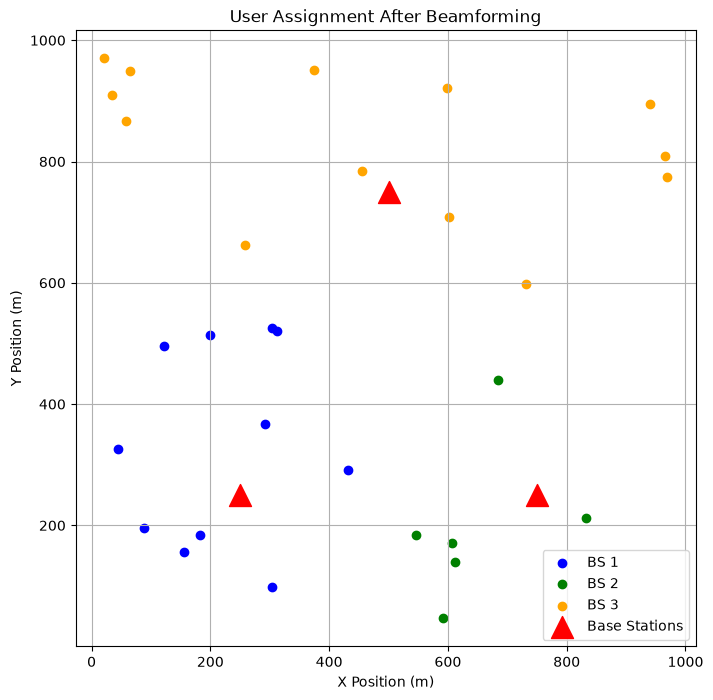

In [ ]:
# Visualize User Assignment
colors = ['blue','green','orange']

plt.figure(figsize=(8,8))

for bs in range(num_bs):

    users = user_positions[
        assignments_beamforming == bs
    ]

    plt.scatter(
        users[:,0],
        users[:,1],
        color=colors[bs],
        label=f"BS {bs+1}"
    )

plt.scatter(
    bs_positions[:,0],
    bs_positions[:,1],
    marker="^",
    s=250,
    color="red",
    label="Base Stations"
)

plt.xlabel("X Position (m)")
plt.ylabel("Y Position (m)")
plt.title("User Assignment After Beamforming")

plt.legend()
plt.grid(True)

plt.savefig(
    "figures_step11_user_assignment_beamforming.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# =======================================================
# STEP 12 - Base Station Load Analysis and Visualization
# =======================================================

# STEP 12.1 - Base Station Load Analysis

num_bs = received_power_beamforming.shape[1]

# Number of users connected to each BS
users_per_bs = np.bincount(
    assignments_beamforming,
    minlength=num_bs
)

print("===== BASE STATION LOAD =====")

for bs in range(num_bs):
    print(f"BS {bs+1}: {users_per_bs[bs]} users")

print("\nTotal Users:", np.sum(users_per_bs))

===== BASE STATION LOAD =====
BS 1: 11 users
BS 2: 6 users
BS 3: 13 users

Total Users: 30


In [ ]:
# STEP 12.2 - Load Percentage

load_percentage = (
    users_per_bs / np.sum(users_per_bs)
) * 100

print("===== BASE STATION LOAD PERCENTAGE =====")

for bs in range(num_bs):
    print(
        f"BS {bs+1}: "
        f"{load_percentage[bs]:.2f}% "
        f"({users_per_bs[bs]} users)"
    )

===== BASE STATION LOAD PERCENTAGE =====
BS 1: 36.67% (11 users)
BS 2: 20.00% (6 users)
BS 3: 43.33% (13 users)


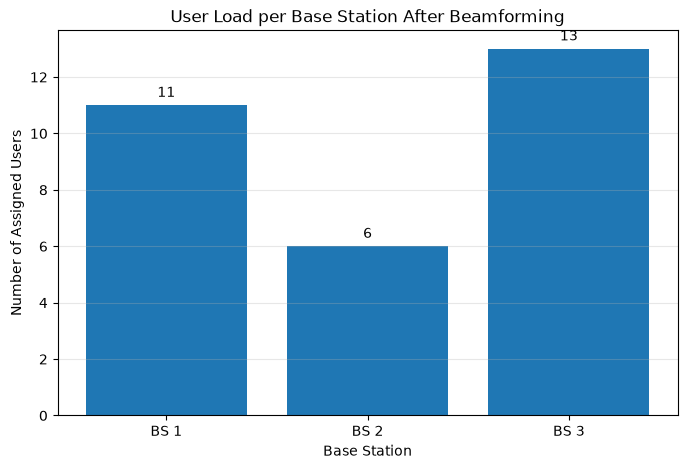

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# STEP 12.3 - Plot Base Station Load

bs_labels = [
    f"BS {i+1}"
    for i in range(num_bs)
]

plt.figure(figsize=(8, 5))

plt.bar(
    bs_labels,
    users_per_bs
)

plt.xlabel("Base Station")
plt.ylabel("Number of Assigned Users")
plt.title("User Load per Base Station After Beamforming")

# Add values above bars
for i, value in enumerate(users_per_bs):
    plt.text(
        i,
        value + 0.3,
        str(value),
        ha="center"
    )

plt.grid(axis="y", alpha=0.3)
plt.savefig("figures_user_load_per_BS_12_3.png", dpi=300, bbox_inches="tight")
plt.show()

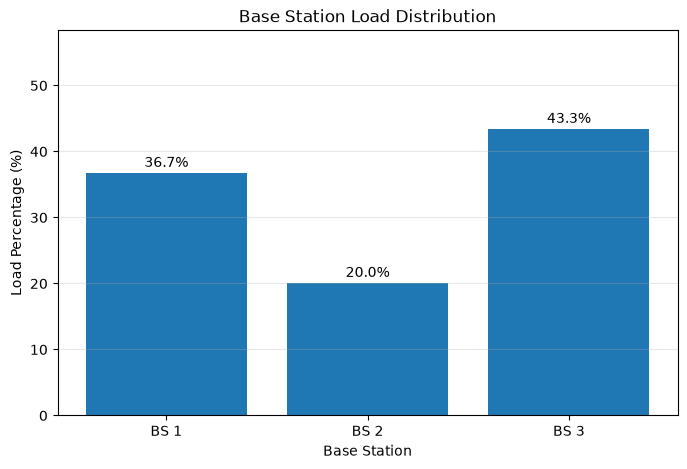

In [ ]:
# STEP 12.4 - Base Station Load Percentage

plt.figure(figsize=(8, 5))

plt.bar(
    bs_labels,
    load_percentage
)

plt.xlabel("Base Station")
plt.ylabel("Load Percentage (%)")
plt.title("Base Station Load Distribution")

for i, value in enumerate(load_percentage):
    plt.text(
        i,
        value + 1,
        f"{value:.1f}%",
        ha="center"
    )

plt.ylim(
    0,
    max(load_percentage) + 15
)

plt.grid(axis="y", alpha=0.3)
plt.savefig("figures_BS_Load_Distribution_12_4.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# ===================================================
# STEP 13 - Realistic Legitimate Traffic Generation
# ===================================================

# STEP 13.1 - Traffic Generation Setup

import numpy as np
import matplotlib.pyplot as plt

# Fixed seed for reproducible traffic generation
np.random.seed(42)

num_users = len(assignments_beamforming)

print("Number of users:", num_users)

Number of users: 30


In [ ]:
# STEP 13.2 - Generate Realistic User Traffic

np.random.seed(100)

# Randomly assign traffic types
traffic_type = np.random.choice(
    ["Low", "Medium", "High"],
    size=num_users,
    p=[0.4, 0.4, 0.2]
)

# Create traffic demand in Mbps
user_traffic = np.zeros(num_users)

for i in range(num_users):

    if traffic_type[i] == "Low":
        user_traffic[i] = np.random.uniform(0.5, 2.0)

    elif traffic_type[i] == "Medium":
        user_traffic[i] = np.random.uniform(2.0, 8.0)

    elif traffic_type[i] == "High":
        user_traffic[i] = np.random.uniform(8.0, 20.0)

print("Traffic generated successfully.")
print("\nFirst 10 users:")

for i in range(min(10, num_users)):
    print(
        f"User {i+1}: "
        f"{traffic_type[i]} traffic, "
        f"{user_traffic[i]:.2f} Mbps"
    )

Traffic generated successfully.

First 10 users:
User 1: Medium traffic, 5.59 Mbps
User 2: Low traffic, 1.41 Mbps
User 3: Medium traffic, 2.63 Mbps
User 4: High traffic, 12.58 Mbps
User 5: Low traffic, 0.55 Mbps
User 6: Low traffic, 1.84 Mbps
User 7: Medium traffic, 7.89 Mbps
User 8: High traffic, 8.72 Mbps
User 9: Low traffic, 1.84 Mbps
User 10: Medium traffic, 5.46 Mbps


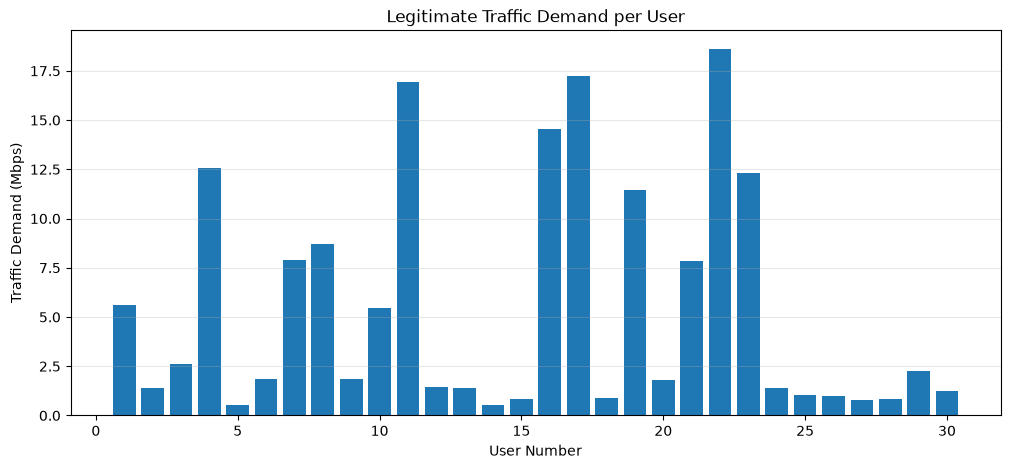

In [ ]:
# STEP 13.3 - Plot Traffic Demand per User

plt.figure(figsize=(12, 5))

plt.bar(
    np.arange(1, num_users + 1),
    user_traffic
)

plt.xlabel("User Number")
plt.ylabel("Traffic Demand (Mbps)")
plt.title("Legitimate Traffic Demand per User")

plt.grid(axis="y", alpha=0.3)
plt.savefig("figures_Legitimate_Traffic_Demand_per_user_13_3.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
assignments_beamforming

# STEP 13.4 - Calculate Traffic Load per Base Station

traffic_per_bs = np.zeros(num_bs)

for bs in range(num_bs):

    # Get users assigned to this BS
    bs_users = (
        assignments_beamforming == bs
    )

    # Sum traffic from assigned users
    traffic_per_bs[bs] = np.sum(
        user_traffic[bs_users]
    )

print("===== LEGITIMATE TRAFFIC PER BASE STATION =====")

for bs in range(num_bs):

    print(
        f"BS {bs+1}: "
        f"{traffic_per_bs[bs]:.2f} Mbps"
    )

print(
    "\nTotal Network Traffic:",
    f"{np.sum(traffic_per_bs):.2f} Mbps"
)

===== LEGITIMATE TRAFFIC PER BASE STATION =====
BS 1: 44.83 Mbps
BS 2: 42.96 Mbps
BS 3: 75.02 Mbps

Total Network Traffic: 162.80 Mbps


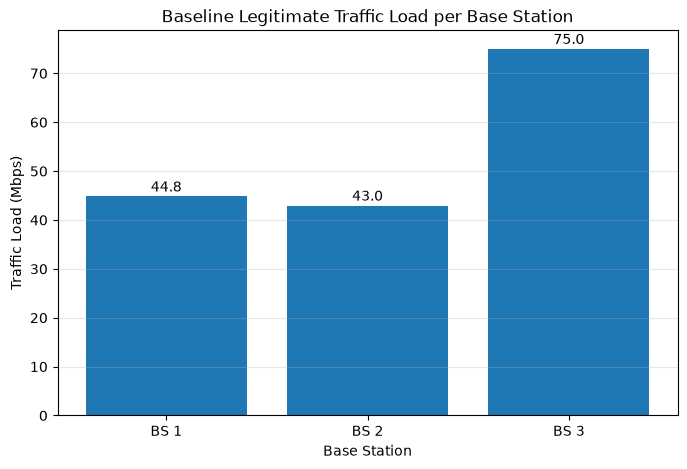

In [ ]:
# STEP 13.5 - Visualize Traffic Load per Base Station

plt.figure(figsize=(8, 5))

plt.bar(
    bs_labels,
    traffic_per_bs
)

plt.xlabel("Base Station")
plt.ylabel("Traffic Load (Mbps)")
plt.title("Baseline Legitimate Traffic Load per Base Station")

# Add traffic values above bars
for i, value in enumerate(traffic_per_bs):

    plt.text(
        i,
        value + 1,
        f"{value:.1f}",
        ha="center"
    )

plt.grid(axis="y", alpha=0.3)
plt.savefig("figures_Baseline_Legitimate_Traffic_Load_Per_BS_13_5.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# STEP 13.6 - User Traffic Summary

import pandas as pd

traffic_summary = pd.DataFrame({
    "User": np.arange(1, num_users + 1),
    "Traffic Type": traffic_type,
    "Traffic Demand (Mbps)": np.round(user_traffic, 2),
    "Assigned BS": assignments_beamforming + 1
})

traffic_summary

,User,Traffic Type,Traffic Demand (Mbps),Assigned BS
0,1,Medium,5.59,3
1,2,Low,1.41,3
2,3,Medium,2.63,1
3,4,High,12.58,3
4,5,Low,0.55,3
5,6,Low,1.84,3
6,7,Medium,7.89,2
7,8,High,8.72,1
8,9,Low,1.84,1
9,10,Medium,5.46,1


In [ ]:
# ===================================================
# STEP 14 - Spoofed Traffic Attack Modelling
# ===================================================

# STEP 14.1 - Check Baseline Legitimate Traffic

print("===== BASELINE LEGITIMATE TRAFFIC =====")

for bs in range(num_bs):
    print(f"BS {bs+1}: {traffic_per_bs[bs]:.2f} Mbps")

total_legitimate_traffic = np.sum(traffic_per_bs)

print(f"\nTotal Legitimate Traffic: {total_legitimate_traffic:.2f} Mbps")

===== BASELINE LEGITIMATE TRAFFIC =====
BS 1: 44.83 Mbps
BS 2: 42.96 Mbps
BS 3: 75.02 Mbps

Total Legitimate Traffic: 162.80 Mbps


In [ ]:
# STEP 14.2 - Define Spoofed Traffic Attack Levels

attack_levels = {
    "Normal": 0.00,
    "Low Attack": 0.25,
    "Medium Attack": 0.50,
    "High Attack": 1.00
}

print("===== ATTACK SCENARIOS =====")

for scenario, level in attack_levels.items():
    print(f"{scenario}: {level*100:.0f}% additional spoofed traffic")

===== ATTACK SCENARIOS =====
Normal: 0% additional spoofed traffic
Low Attack: 25% additional spoofed traffic
Medium Attack: 50% additional spoofed traffic
High Attack: 100% additional spoofed traffic


In [ ]:
# STEP 14.3 - Generate Spoofed Traffic Per Base Station

np.random.seed(200)

spoofed_traffic_results = {}

for scenario, attack_level in attack_levels.items():

    # Calculate total spoofed traffic
    total_spoofed_traffic = (
        total_legitimate_traffic * attack_level
    )

    # Randomly distribute spoofed traffic among base stations
    distribution = np.random.dirichlet(
        np.ones(num_bs)
    )

    spoofed_traffic_per_bs = (
        total_spoofed_traffic * distribution
    )

    spoofed_traffic_results[scenario] = spoofed_traffic_per_bs

    print(f"\n{scenario}")

    for bs in range(num_bs):
        print(
            f"BS {bs+1}: "
            f"{spoofed_traffic_per_bs[bs]:.2f} Mbps spoofed traffic"
        )


Normal
BS 1: 0.00 Mbps spoofed traffic
BS 2: 0.00 Mbps spoofed traffic
BS 3: 0.00 Mbps spoofed traffic

Low Attack
BS 1: 11.34 Mbps spoofed traffic
BS 2: 29.30 Mbps spoofed traffic
BS 3: 0.06 Mbps spoofed traffic

Medium Attack
BS 1: 10.42 Mbps spoofed traffic
BS 2: 56.64 Mbps spoofed traffic
BS 3: 14.34 Mbps spoofed traffic

High Attack
BS 1: 63.34 Mbps spoofed traffic
BS 2: 31.94 Mbps spoofed traffic
BS 3: 67.52 Mbps spoofed traffic


In [ ]:
# STEP 14.4 - Calculate Total Traffic During Each Attack

total_traffic_results = {}

for scenario in attack_levels:

    spoofed_traffic = spoofed_traffic_results[scenario]

    total_traffic = (
        traffic_per_bs +
        spoofed_traffic
    )

    total_traffic_results[scenario] = total_traffic

    print(f"\n===== {scenario.upper()} =====")

    for bs in range(num_bs):
        print(
            f"BS {bs+1}: "
            f"{total_traffic[bs]:.2f} Mbps"
        )

    print(
        f"Total Network Traffic: "
        f"{np.sum(total_traffic):.2f} Mbps"
    )


===== NORMAL =====
BS 1: 44.83 Mbps
BS 2: 42.96 Mbps
BS 3: 75.02 Mbps
Total Network Traffic: 162.80 Mbps

===== LOW ATTACK =====
BS 1: 56.17 Mbps
BS 2: 72.26 Mbps
BS 3: 75.07 Mbps
Total Network Traffic: 203.50 Mbps

===== MEDIUM ATTACK =====
BS 1: 55.25 Mbps
BS 2: 99.60 Mbps
BS 3: 89.36 Mbps
Total Network Traffic: 244.21 Mbps

===== HIGH ATTACK =====
BS 1: 108.17 Mbps
BS 2: 74.90 Mbps
BS 3: 142.54 Mbps
Total Network Traffic: 325.61 Mbps


In [ ]:
# STEP 14.5 - Create Attack Scenario Results Table

import pandas as pd

attack_summary = pd.DataFrame({
    "Scenario": list(attack_levels.keys()),
    "BS 1 Traffic (Mbps)": [
        total_traffic_results[s][0]
        for s in attack_levels
    ],
    "BS 2 Traffic (Mbps)": [
        total_traffic_results[s][1]
        for s in attack_levels
    ],
    "BS 3 Traffic (Mbps)": [
        total_traffic_results[s][2]
        for s in attack_levels
    ],
    "Total Network Traffic (Mbps)": [
        np.sum(total_traffic_results[s])
        for s in attack_levels
    ]
})

attack_summary = attack_summary.round(2)

attack_summary

,Scenario,BS 1 Traffic (Mbps),BS 2 Traffic (Mbps),BS 3 Traffic (Mbps),Total Network Traffic (Mbps)
0,Normal,44.83,42.96,75.02,162.80
1,Low Attack,56.17,72.26,75.07,203.50
2,Medium Attack,55.25,99.60,89.36,244.21
3,High Attack,108.17,74.90,142.54,325.61


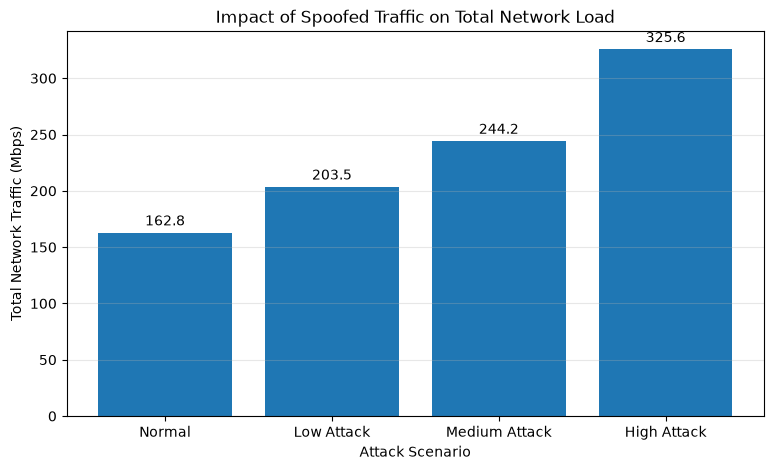

In [ ]:
# STEP 14.6 - Compare Total Network Traffic

scenario_names = list(attack_levels.keys())

total_network_traffic = [
    np.sum(total_traffic_results[scenario])
    for scenario in scenario_names
]

plt.figure(figsize=(9, 5))

plt.bar(
    scenario_names,
    total_network_traffic
)

plt.xlabel("Attack Scenario")
plt.ylabel("Total Network Traffic (Mbps)")
plt.title("Impact of Spoofed Traffic on Total Network Load")

for i, value in enumerate(total_network_traffic):
    plt.text(
        i,
        value + max(total_network_traffic) * 0.02,
        f"{value:.1f}",
        ha="center"
    )

plt.grid(axis="y", alpha=0.3)
plt.savefig("figures_Impact_Of_Spoofed_Traffic_on_Total_Network_Load_14_6.png", dpi=300, bbox_inches="tight")
plt.show()

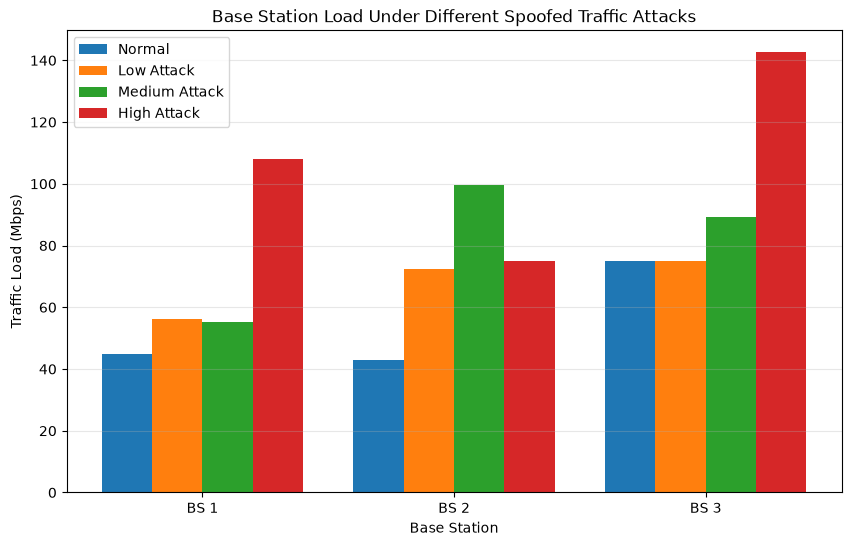

In [ ]:
# STEP 14.7 - Compare Base Station Traffic Under Different Attacks

x = np.arange(num_bs)

width = 0.2

plt.figure(figsize=(10, 6))

for i, scenario in enumerate(scenario_names):

    plt.bar(
        x + i * width,
        total_traffic_results[scenario],
        width,
        label=scenario
    )

plt.xticks(
    x + width * 1.5,
    [f"BS {i+1}" for i in range(num_bs)]
)

plt.xlabel("Base Station")
plt.ylabel("Traffic Load (Mbps)")
plt.title("Base Station Load Under Different Spoofed Traffic Attacks")

plt.legend()

plt.grid(axis="y", alpha=0.3)
plt.savefig("figures_BS_Load_Under_Different_Attacks_14_7.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# ========================================================
# STEP 15 - Base Station Capacity and Congestion Analysis
# ========================================================
# STEP 15.1 - Define Base Station Capacity

bs_capacity = np.full(
    num_bs,
    100.0
)

print("===== BASE STATION CAPACITY =====")

for bs in range(num_bs):
    print(
        f"BS {bs+1}: "
        f"{bs_capacity[bs]:.1f} Mbps"
    )

===== BASE STATION CAPACITY =====
BS 1: 100.0 Mbps
BS 2: 100.0 Mbps
BS 3: 100.0 Mbps


In [ ]:
# STEP 15.2 - Calculate BS Capacity Utilization

utilization_results = {}

for scenario in scenario_names:

    utilization = (
        total_traffic_results[scenario]
        / bs_capacity
    ) * 100

    utilization_results[scenario] = utilization

    print(f"\n===== {scenario.upper()} =====")

    for bs in range(num_bs):

        print(
            f"BS {bs+1}: "
            f"{utilization[bs]:.2f}% utilization"
        )


===== NORMAL =====
BS 1: 44.83% utilization
BS 2: 42.96% utilization
BS 3: 75.02% utilization

===== LOW ATTACK =====
BS 1: 56.17% utilization
BS 2: 72.26% utilization
BS 3: 75.07% utilization

===== MEDIUM ATTACK =====
BS 1: 55.25% utilization
BS 2: 99.60% utilization
BS 3: 89.36% utilization

===== HIGH ATTACK =====
BS 1: 108.17% utilization
BS 2: 74.90% utilization
BS 3: 142.54% utilization


In [ ]:
# STEP 15.3 - Detect Congested Base Stations

congestion_results = {}

for scenario in scenario_names:

    utilization = utilization_results[scenario]

    congestion_status = utilization > 100

    congestion_results[scenario] = congestion_status

    print(f"\n===== {scenario.upper()} =====")

    for bs in range(num_bs):

        if congestion_status[bs]:

            print(
                f"BS {bs+1}: CONGESTED "
                f"({utilization[bs]:.1f}%)"
            )

        else:

            print(
                f"BS {bs+1}: Normal "
                f"({utilization[bs]:.1f}%)"
            )


===== NORMAL =====
BS 1: Normal (44.8%)
BS 2: Normal (43.0%)
BS 3: Normal (75.0%)

===== LOW ATTACK =====
BS 1: Normal (56.2%)
BS 2: Normal (72.3%)
BS 3: Normal (75.1%)

===== MEDIUM ATTACK =====
BS 1: Normal (55.2%)
BS 2: Normal (99.6%)
BS 3: Normal (89.4%)

===== HIGH ATTACK =====
BS 1: CONGESTED (108.2%)
BS 2: Normal (74.9%)
BS 3: CONGESTED (142.5%)


In [ ]:
# STEP 15.4 - Calculate Excess Traffic

excess_traffic_results = {}

for scenario in scenario_names:

    excess_traffic = np.maximum(
        total_traffic_results[scenario]
        - bs_capacity,
        0
    )

    excess_traffic_results[scenario] = excess_traffic

    print(f"\n===== {scenario.upper()} =====")

    for bs in range(num_bs):

        print(
            f"BS {bs+1}: "
            f"{excess_traffic[bs]:.2f} Mbps excess traffic"
        )


===== NORMAL =====
BS 1: 0.00 Mbps excess traffic
BS 2: 0.00 Mbps excess traffic
BS 3: 0.00 Mbps excess traffic

===== LOW ATTACK =====
BS 1: 0.00 Mbps excess traffic
BS 2: 0.00 Mbps excess traffic
BS 3: 0.00 Mbps excess traffic

===== MEDIUM ATTACK =====
BS 1: 0.00 Mbps excess traffic
BS 2: 0.00 Mbps excess traffic
BS 3: 0.00 Mbps excess traffic

===== HIGH ATTACK =====
BS 1: 8.17 Mbps excess traffic
BS 2: 0.00 Mbps excess traffic
BS 3: 42.54 Mbps excess traffic


In [ ]:
# STEP 15.5 - Calculate Available Capacity

available_capacity_results = {}

for scenario in scenario_names:

    available_capacity = np.maximum(
        bs_capacity -
        total_traffic_results[scenario],
        0
    )

    available_capacity_results[scenario] = available_capacity

    print(f"\n===== {scenario.upper()} =====")

    for bs in range(num_bs):

        print(
            f"BS {bs+1}: "
            f"{available_capacity[bs]:.2f} Mbps available"
        )


===== NORMAL =====
BS 1: 55.17 Mbps available
BS 2: 57.04 Mbps available
BS 3: 24.98 Mbps available

===== LOW ATTACK =====
BS 1: 43.83 Mbps available
BS 2: 27.74 Mbps available
BS 3: 24.93 Mbps available

===== MEDIUM ATTACK =====
BS 1: 44.75 Mbps available
BS 2: 0.40 Mbps available
BS 3: 10.64 Mbps available

===== HIGH ATTACK =====
BS 1: 0.00 Mbps available
BS 2: 25.10 Mbps available
BS 3: 0.00 Mbps available


In [ ]:
# STEP 15.6 - Create Capacity Summary Table

capacity_summary_list = []

for scenario in scenario_names:

    for bs in range(num_bs):

        load = total_traffic_results[scenario][bs]

        utilization = utilization_results[scenario][bs]

        excess = excess_traffic_results[scenario][bs]

        available = available_capacity_results[scenario][bs]

        if utilization < 70:
            status = "Normal"

        elif utilization < 90:
            status = "High Load"

        elif utilization <= 100:
            status = "Critical"

        else:
            status = "Congested"

        capacity_summary_list.append({
            "Scenario": scenario,
            "Base Station": f"BS {bs+1}",
            "Traffic Load (Mbps)": round(load, 2),
            "Capacity (Mbps)": round(bs_capacity[bs], 2),
            "Utilization (%)": round(utilization, 2),
            "Available Capacity (Mbps)": round(available, 2),
            "Excess Traffic (Mbps)": round(excess, 2),
            "Status": status
        })

capacity_summary = pd.DataFrame(
    capacity_summary_list
)

capacity_summary

,Scenario,Base Station,Traffic Load (Mbps),Capacity (Mbps),Utilization (%),Available Capacity (Mbps),Excess Traffic (Mbps),Status
0,Normal,BS 1,44.83,100.0,44.83,55.17,0.00,Normal
1,Normal,BS 2,42.96,100.0,42.96,57.04,0.00,Normal
2,Normal,BS 3,75.02,100.0,75.02,24.98,0.00,High Load
3,Low Attack,BS 1,56.17,100.0,56.17,43.83,0.00,Normal
4,Low Attack,BS 2,72.26,100.0,72.26,27.74,0.00,High Load
5,Low Attack,BS 3,75.07,100.0,75.07,24.93,0.00,High Load
6,Medium Attack,BS 1,55.25,100.0,55.25,44.75,0.00,Normal
7,Medium Attack,BS 2,99.60,100.0,99.60,0.40,0.00,Critical
8,Medium Attack,BS 3,89.36,100.0,89.36,10.64,0.00,High Load
9,High Attack,BS 1,108.17,100.0,108.17,0.00,8.17,Congested


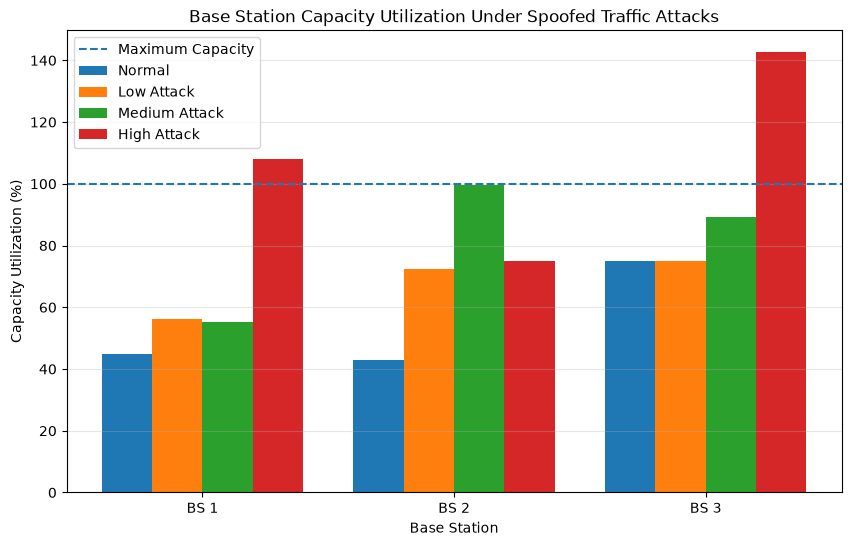

In [ ]:
# STEP 15.7 - Plot BS Capacity Utilization

x = np.arange(num_bs)
width = 0.2

plt.figure(figsize=(10, 6))

for i, scenario in enumerate(scenario_names):

    plt.bar(
        x + i * width,
        utilization_results[scenario],
        width,
        label=scenario
    )

# Capacity limit line
plt.axhline(
    y=100,
    linestyle="--",
    label="Maximum Capacity"
)

plt.xticks(
    x + width * 1.5,
    [f"BS {i+1}" for i in range(num_bs)]
)

plt.xlabel("Base Station")
plt.ylabel("Capacity Utilization (%)")
plt.title(
    "Base Station Capacity Utilization Under Spoofed Traffic Attacks"
)

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.savefig("figures_BS_Capacity_Utilization_Under_Attacks_15_7.png", dpi=300, bbox_inches="tight")
plt.show()

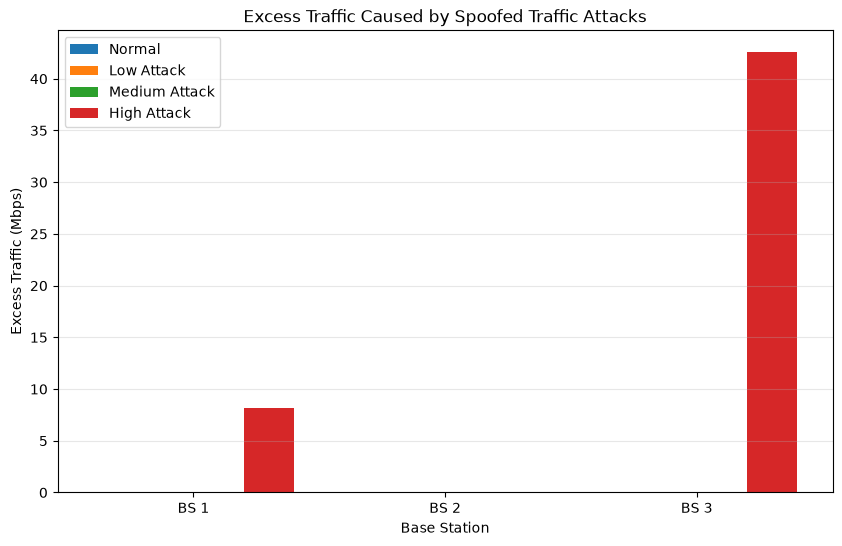

In [ ]:
# STEP 15.8 - Plot Excess Traffic

plt.figure(figsize=(10, 6))

for i, scenario in enumerate(scenario_names):

    plt.bar(
        x + i * width,
        excess_traffic_results[scenario],
        width,
        label=scenario
    )

plt.xticks(
    x + width * 1.5,
    [f"BS {i+1}" for i in range(num_bs)]
)

plt.xlabel("Base Station")
plt.ylabel("Excess Traffic (Mbps)")
plt.title(
    "Excess Traffic Caused by Spoofed Traffic Attacks"
)

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.savefig("figures_Excess_Traffic_Caused_by_Attacks_15_8.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# ==================================
# STEP 16 - QoS Impact Assessment
# ==================================
# STEP 16.1 - Calculate Achieved Throughput

throughput_results = {}

for scenario in scenario_names:

    achieved_throughput = np.minimum(
        total_traffic_results[scenario],
        bs_capacity
    )

    throughput_results[scenario] = achieved_throughput

    print(f"\n===== {scenario.upper()} =====")

    for bs in range(num_bs):

        print(
            f"BS {bs+1}: "
            f"{achieved_throughput[bs]:.2f} Mbps"
        )

    print(
        f"Total Achieved Throughput: "
        f"{np.sum(achieved_throughput):.2f} Mbps"
    )


===== NORMAL =====
BS 1: 44.83 Mbps
BS 2: 42.96 Mbps
BS 3: 75.02 Mbps
Total Achieved Throughput: 162.80 Mbps

===== LOW ATTACK =====
BS 1: 56.17 Mbps
BS 2: 72.26 Mbps
BS 3: 75.07 Mbps
Total Achieved Throughput: 203.50 Mbps

===== MEDIUM ATTACK =====
BS 1: 55.25 Mbps
BS 2: 99.60 Mbps
BS 3: 89.36 Mbps
Total Achieved Throughput: 244.21 Mbps

===== HIGH ATTACK =====
BS 1: 100.00 Mbps
BS 2: 74.90 Mbps
BS 3: 100.00 Mbps
Total Achieved Throughput: 274.90 Mbps


In [ ]:
# STEP 16.2 - Calculate Throughput Degradation

normal_total_throughput = np.sum(
    throughput_results["Normal"]
)

throughput_degradation_results = {}

for scenario in scenario_names:

    current_throughput = np.sum(
        throughput_results[scenario]
    )

    degradation = (
        (normal_total_throughput - current_throughput)
        / normal_total_throughput
    ) * 100

    # Prevent negative degradation
    degradation = max(degradation, 0)

    throughput_degradation_results[scenario] = degradation

    print(
        f"{scenario}: "
        f"{degradation:.2f}% throughput degradation"
    )

Normal: 0.00% throughput degradation
Low Attack: 0.00% throughput degradation
Medium Attack: 0.00% throughput degradation
High Attack: 0.00% throughput degradation


In [ ]:
# STEP 16.3 - Calculate Packet Loss Rate

packet_loss_results = {}

for scenario in scenario_names:

    traffic_load = total_traffic_results[scenario]

    excess_traffic = excess_traffic_results[scenario]

    packet_loss = (
        excess_traffic /
        np.maximum(traffic_load, 0.001)
    ) * 100

    packet_loss_results[scenario] = packet_loss

    print(f"\n===== {scenario.upper()} =====")

    for bs in range(num_bs):

        print(
            f"BS {bs+1}: "
            f"{packet_loss[bs]:.2f}% packet loss"
        )


===== NORMAL =====
BS 1: 0.00% packet loss
BS 2: 0.00% packet loss
BS 3: 0.00% packet loss

===== LOW ATTACK =====
BS 1: 0.00% packet loss
BS 2: 0.00% packet loss
BS 3: 0.00% packet loss

===== MEDIUM ATTACK =====
BS 1: 0.00% packet loss
BS 2: 0.00% packet loss
BS 3: 0.00% packet loss

===== HIGH ATTACK =====
BS 1: 7.56% packet loss
BS 2: 0.00% packet loss
BS 3: 29.84% packet loss


In [ ]:
# STEP 16.4 - Calculate Average Packet Loss

average_packet_loss_results = {}

for scenario in scenario_names:

    average_loss = np.mean(
        packet_loss_results[scenario]
    )

    average_packet_loss_results[scenario] = average_loss

    print(
        f"{scenario}: "
        f"{average_loss:.2f}% average packet loss"
    )

Normal: 0.00% average packet loss
Low Attack: 0.00% average packet loss
Medium Attack: 0.00% average packet loss
High Attack: 12.47% average packet loss


In [ ]:
# STEP 16.5 - Calculate Latency Based on Utilization

base_latency = 10.0  # milliseconds

latency_results = {}

for scenario in scenario_names:

    utilization = utilization_results[scenario]

    # Avoid division by zero
    safe_utilization = np.minimum(
        utilization,
        99
    )

    latency = (
        base_latency /
        (1 - safe_utilization / 100)
    )

    # Apply congestion penalty
    congestion = utilization >= 100

    latency[congestion] = (
        base_latency *
        (1 + utilization[congestion] / 50)
    )

    latency_results[scenario] = latency

    print(f"\n===== {scenario.upper()} =====")

    for bs in range(num_bs):

        print(
            f"BS {bs+1}: "
            f"{latency[bs]:.2f} ms"
        )


===== NORMAL =====
BS 1: 18.13 ms
BS 2: 17.53 ms
BS 3: 40.03 ms

===== LOW ATTACK =====
BS 1: 22.82 ms
BS 2: 36.05 ms
BS 3: 40.12 ms

===== MEDIUM ATTACK =====
BS 1: 22.35 ms
BS 2: 1000.00 ms
BS 3: 93.99 ms

===== HIGH ATTACK =====
BS 1: 31.63 ms
BS 2: 39.83 ms
BS 3: 38.51 ms


In [ ]:
# STEP 16.6 - Calculate Average Latency

average_latency_results = {}

for scenario in scenario_names:

    average_latency = np.mean(
        latency_results[scenario]
    )

    average_latency_results[scenario] = average_latency

    print(
        f"{scenario}: "
        f"{average_latency:.2f} ms"
    )

Normal: 25.23 ms
Low Attack: 32.99 ms
Medium Attack: 372.11 ms
High Attack: 36.66 ms


In [ ]:
# STEP 16.7 - Create QoS Summary Table

qos_summary = pd.DataFrame({

    "Scenario": scenario_names,

    "Traffic Demand (Mbps)": [
        np.sum(total_traffic_results[s])
        for s in scenario_names
    ],

    "Achieved Throughput (Mbps)": [
        np.sum(throughput_results[s])
        for s in scenario_names
    ],

    "Throughput Degradation (%)": [
        throughput_degradation_results[s]
        for s in scenario_names
    ],

    "Average Latency (ms)": [
        average_latency_results[s]
        for s in scenario_names
    ],

    "Average Packet Loss (%)": [
        average_packet_loss_results[s]
        for s in scenario_names
    ]
})

qos_summary = qos_summary.round(2)

qos_summary

,Scenario,Traffic Demand (Mbps),Achieved Throughput (Mbps),Throughput Degradation (%),Average Latency (ms),Average Packet Loss (%)
0,Normal,162.80,162.80,0.0,25.23,0.00
1,Low Attack,203.50,203.50,0.0,32.99,0.00
2,Medium Attack,244.21,244.21,0.0,372.11,0.00
3,High Attack,325.61,274.90,0.0,36.66,12.47


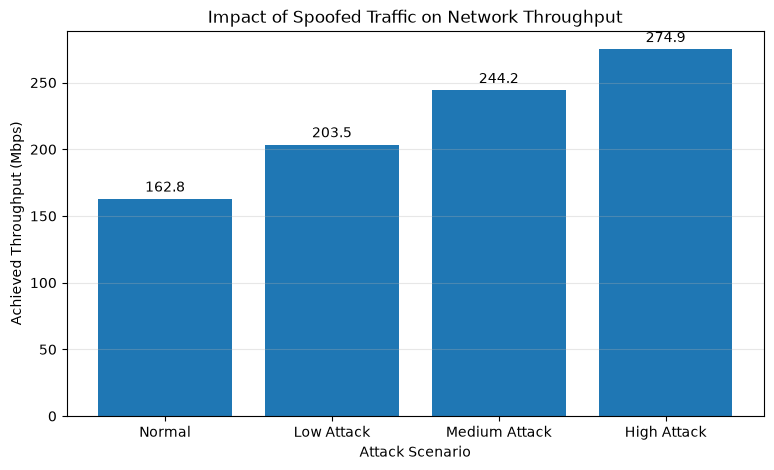

In [ ]:
# STEP 16.8 - Plot Total Achieved Throughput

total_throughput = [
    np.sum(throughput_results[s])
    for s in scenario_names
]

plt.figure(figsize=(9, 5))

plt.bar(
    scenario_names,
    total_throughput
)

plt.xlabel("Attack Scenario")
plt.ylabel("Achieved Throughput (Mbps)")
plt.title(
    "Impact of Spoofed Traffic on Network Throughput"
)

plt.grid(axis="y", alpha=0.3)

for i, value in enumerate(total_throughput):

    plt.text(
        i,
        value + max(total_throughput) * 0.02,
        f"{value:.1f}",
        ha="center"
    )
plt.savefig("figures_Impact_of_Spoofed_Traffic_on_Network_Throughput_16_8.png", dpi=300, bbox_inches="tight")
plt.show()

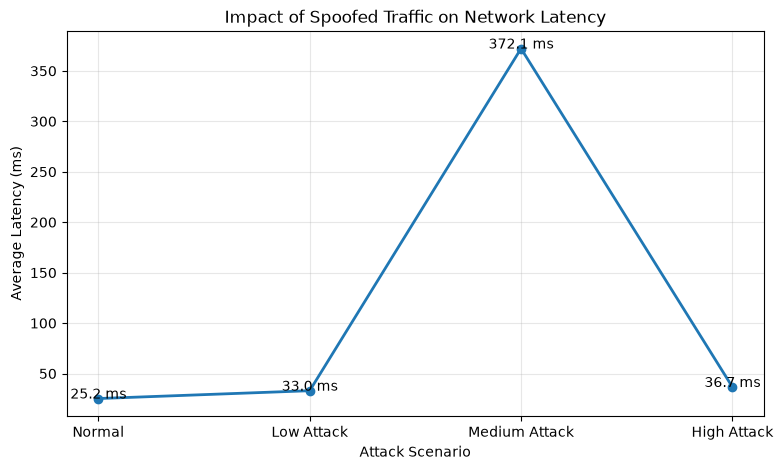

In [ ]:
# STEP 16.9 - Plot Average Network Latency

average_latency = [
    average_latency_results[s]
    for s in scenario_names
]

plt.figure(figsize=(9, 5))

plt.plot(
    scenario_names,
    average_latency,
    marker="o",
    linewidth=2
)

plt.xlabel("Attack Scenario")
plt.ylabel("Average Latency (ms)")
plt.title(
    "Impact of Spoofed Traffic on Network Latency"
)

plt.grid(True, alpha=0.3)

for i, value in enumerate(average_latency):

    plt.text(
        i,
        value,
        f"{value:.1f} ms",
        ha="center"
    )
plt.savefig("figures_Impact_of_Spoofed_Traffic_on_Network_Latency_16_9.png", dpi=300, bbox_inches="tight")
plt.show()

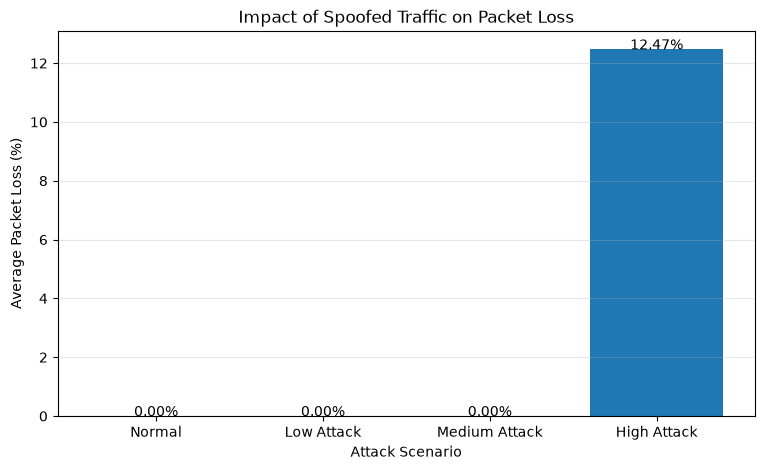

In [ ]:
# STEP 16.10 - Plot Average Packet Loss

average_packet_loss = [
    average_packet_loss_results[s]
    for s in scenario_names
]

plt.figure(figsize=(9, 5))

plt.bar(
    scenario_names,
    average_packet_loss
)

plt.xlabel("Attack Scenario")
plt.ylabel("Average Packet Loss (%)")
plt.title(
    "Impact of Spoofed Traffic on Packet Loss"
)

plt.grid(axis="y", alpha=0.3)

for i, value in enumerate(average_packet_loss):

    plt.text(
        i,
        value,
        f"{value:.2f}%",
        ha="center"
    )
plt.savefig("figures_Impact_of_Spoofed_Traffic_on_Packet_Loss_16_10.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# ==========================================================
# STEP 17 - User Reassignment Under Spoofed Traffic Attacks
# ==========================================================
# STEP 17.1 - Save Original User Assignment

original_assignments = assignments_beamforming.copy()

print("Original assignments saved successfully.")

for user in range(min(10, num_users)):
    print(
        f"User {user+1} → "
        f"BS {original_assignments[user] + 1}"
    )

Original assignments saved successfully.
User 1 → BS 3
User 2 → BS 3
User 3 → BS 1
User 4 → BS 3
User 5 → BS 3
User 6 → BS 3
User 7 → BS 2
User 8 → BS 1
User 9 → BS 1
User 10 → BS 1


In [ ]:
# STEP 17.2 - Load-Aware User Reassignment Function

def reassign_users(
    initial_assignments,
    user_traffic,
    received_power,
    initial_load,
    bs_capacity
):

    # Copy original assignments
    new_assignments = initial_assignments.copy()

    # Copy current traffic load
    current_load = initial_load.copy()

    num_users = len(initial_assignments)
    num_bs = len(bs_capacity)

    reassigned_users = []

    # Find overloaded base stations
    overloaded_bs = np.where(
        current_load > bs_capacity
    )[0]

    print("Overloaded Base Stations:", overloaded_bs + 1)

    # Process each overloaded BS
    for overloaded in overloaded_bs:

        # Find users currently connected to this BS
        users_on_bs = np.where(
            new_assignments == overloaded
        )[0]

        # Sort users by traffic demand
        # Larger traffic users are considered first
        users_sorted = users_on_bs[
            np.argsort(user_traffic[users_on_bs])[::-1]
        ]

        for user in users_sorted:

            # Check if overload is resolved
            if current_load[overloaded] <= bs_capacity[overloaded]:
                break

            # Get all candidate BSs except current BS
            candidate_bs = [
                bs for bs in range(num_bs)
                if bs != overloaded
            ]

            # Sort candidate BSs based on received power
            candidate_bs = sorted(
                candidate_bs,
                key=lambda bs: received_power[user, bs],
                reverse=True
            )

            # Try each candidate BS
            for target_bs in candidate_bs:

                # Check whether target BS has enough available capacity
                if (
                    current_load[target_bs]
                    + user_traffic[user]
                    <= bs_capacity[target_bs]
                ):

                    # Move the user
                    new_assignments[user] = target_bs

                    # Update loads
                    current_load[overloaded] -= user_traffic[user]

                    current_load[target_bs] += user_traffic[user]

                    # Save reassignment information
                    reassigned_users.append({
                        "User": user + 1,
                        "From BS": overloaded + 1,
                        "To BS": target_bs + 1,
                        "Traffic (Mbps)": user_traffic[user]
                    })

                    break

    return (
        new_assignments,
        current_load,
        reassigned_users
    )

In [ ]:
# STEP 17.3 - Apply User Reassignment

reassignment_results = {}

for scenario in scenario_names:

    print("\n" + "=" * 50)
    print(f"SCENARIO: {scenario.upper()}")
    print("=" * 50)

    # Original traffic load including spoofed traffic
    initial_load = total_traffic_results[scenario].copy()

    (
        new_assignments,
        new_load,
        reassigned_users
    ) = reassign_users(
        original_assignments,
        user_traffic,
        received_power_beamforming,
        initial_load,
        bs_capacity
    )

    reassignment_results[scenario] = {
        "assignments": new_assignments,
        "load": new_load,
        "reassigned_users": reassigned_users
    }

    print(
        f"\nNumber of reassigned users: "
        f"{len(reassigned_users)}"
    )


SCENARIO: NORMAL
Overloaded Base Stations: []

Number of reassigned users: 0

SCENARIO: LOW ATTACK
Overloaded Base Stations: []

Number of reassigned users: 0

SCENARIO: MEDIUM ATTACK
Overloaded Base Stations: []

Number of reassigned users: 0

SCENARIO: HIGH ATTACK
Overloaded Base Stations: [1 3]

Number of reassigned users: 5


In [ ]:
# STEP 17.4 - Display Reassignment Details

for scenario in scenario_names:

    reassigned_users = (
        reassignment_results[scenario]
        ["reassigned_users"]
    )

    print("\n" + "=" * 50)
    print(scenario.upper())
    print("=" * 50)

    if len(reassigned_users) == 0:

        print("No users were reassigned.")

    else:

        reassignment_df = pd.DataFrame(
            reassigned_users
        )

        print(reassignment_df)


NORMAL
No users were reassigned.

LOW ATTACK
No users were reassigned.

MEDIUM ATTACK
No users were reassigned.

HIGH ATTACK
   User  From BS  To BS  Traffic (Mbps)
0    19        1      2       11.430748
1     4        3      2       12.583321
2     6        3      1        1.835617
3     2        3      1        1.405707
4    26        3      2        1.010285


In [ ]:
# STEP 17.5 - Count Users per BS Before and After Reassignment

assignment_comparison = []

for scenario in scenario_names:

    new_assignments = (
        reassignment_results[scenario]
        ["assignments"]
    )

    users_before = np.bincount(
        original_assignments,
        minlength=num_bs
    )

    users_after = np.bincount(
        new_assignments,
        minlength=num_bs
    )

    for bs in range(num_bs):

        assignment_comparison.append({
            "Scenario": scenario,
            "Base Station": f"BS {bs+1}",
            "Users Before": users_before[bs],
            "Users After": users_after[bs],
            "Change": users_after[bs] - users_before[bs]
        })

assignment_comparison_df = pd.DataFrame(
    assignment_comparison
)

assignment_comparison_df

,Scenario,Base Station,Users Before,Users After,Change
0,Normal,BS 1,11,11,0
1,Normal,BS 2,6,6,0
2,Normal,BS 3,13,13,0
3,Low Attack,BS 1,11,11,0
4,Low Attack,BS 2,6,6,0
5,Low Attack,BS 3,13,13,0
6,Medium Attack,BS 1,11,11,0
7,Medium Attack,BS 2,6,6,0
8,Medium Attack,BS 3,13,13,0
9,High Attack,BS 1,11,12,1


In [ ]:
# STEP 17.6 - Compare Load Before and After Reassignment

load_comparison = []

for scenario in scenario_names:

    before_load = total_traffic_results[scenario]

    after_load = (
        reassignment_results[scenario]
        ["load"]
    )

    for bs in range(num_bs):

        load_comparison.append({
            "Scenario": scenario,
            "Base Station": f"BS {bs+1}",
            "Load Before (Mbps)": round(
                before_load[bs], 2
            ),
            "Load After (Mbps)": round(
                after_load[bs], 2
            ),
            "Capacity (Mbps)": bs_capacity[bs]
        })

load_comparison_df = pd.DataFrame(
    load_comparison
)

load_comparison_df

,Scenario,Base Station,Load Before (Mbps),Load After (Mbps),Capacity (Mbps)
0,Normal,BS 1,44.83,44.83,100.0
1,Normal,BS 2,42.96,42.96,100.0
2,Normal,BS 3,75.02,75.02,100.0
3,Low Attack,BS 1,56.17,56.17,100.0
4,Low Attack,BS 2,72.26,72.26,100.0
5,Low Attack,BS 3,75.07,75.07,100.0
6,Medium Attack,BS 1,55.25,55.25,100.0
7,Medium Attack,BS 2,99.60,99.60,100.0
8,Medium Attack,BS 3,89.36,89.36,100.0
9,High Attack,BS 1,108.17,99.98,100.0


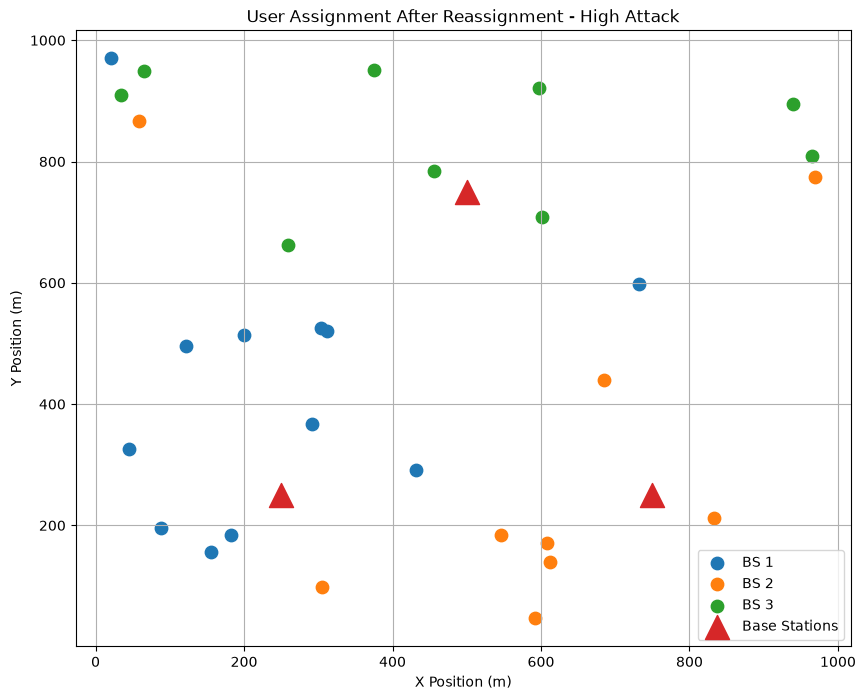

In [ ]:
# STEP 17.7 - Visualize User Assignment Changes

scenario_to_plot = "High Attack"

new_assignments = (
    reassignment_results[scenario_to_plot]
    ["assignments"]
)

plt.figure(figsize=(10, 8))

for bs in range(num_bs):

    users = user_positions[
        new_assignments == bs
    ]

    plt.scatter(
        users[:, 0],
        users[:, 1],
        s=80,
        label=f"BS {bs+1}"
    )

# Plot base stations
plt.scatter(
    bs_positions[:, 0],
    bs_positions[:, 1],
    marker="^",
    s=300,
    label="Base Stations"
)

plt.xlabel("X Position (m)")
plt.ylabel("Y Position (m)")
plt.title(
    f"User Assignment After Reassignment - {scenario_to_plot}"
)

plt.grid(True)
plt.legend()
plt.savefig("figures_User_Assignment_After_Reassignment_High_Attack_17_7.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# STEP 17.8 - Number of Users Whose Assignment Changed

assignment_change_results = {}

for scenario in scenario_names:

    new_assignments = (
        reassignment_results[scenario]
        ["assignments"]
    )

    changed_users = np.sum(
        new_assignments != original_assignments
    )

    assignment_change_results[scenario] = changed_users

    print(
        f"{scenario}: "
        f"{changed_users} users reassigned"
    )

Normal: 0 users reassigned
Low Attack: 0 users reassigned
Medium Attack: 0 users reassigned
High Attack: 5 users reassigned


In [ ]:
# ============================================================
# STEP 18 - QoS Comparison Before and After User Reassignment
# ============================================================
# STEP 18.1 - BS Utilization After Reassignment

utilization_after_reassignment = {}

for scenario in scenario_names:

    load_after = reassignment_results[scenario]["load"]

    utilization_after = (
        load_after / bs_capacity
    ) * 100

    utilization_after_reassignment[scenario] = utilization_after

    print(f"\n===== {scenario.upper()} =====")

    for bs in range(num_bs):
        print(
            f"BS {bs+1}: "
            f"{utilization_after[bs]:.2f}% utilization"
        )


===== NORMAL =====
BS 1: 44.83% utilization
BS 2: 42.96% utilization
BS 3: 75.02% utilization

===== LOW ATTACK =====
BS 1: 56.17% utilization
BS 2: 72.26% utilization
BS 3: 75.07% utilization

===== MEDIUM ATTACK =====
BS 1: 55.25% utilization
BS 2: 99.60% utilization
BS 3: 89.36% utilization

===== HIGH ATTACK =====
BS 1: 99.98% utilization
BS 2: 99.92% utilization
BS 3: 125.70% utilization


In [ ]:
# STEP 18.2 - Achieved Throughput After Reassignment

throughput_after_reassignment = {}

for scenario in scenario_names:

    load_after = reassignment_results[scenario]["load"]

    achieved_throughput = np.minimum(
        load_after,
        bs_capacity
    )

    throughput_after_reassignment[scenario] = (
        achieved_throughput
    )

    print(f"\n===== {scenario.upper()} =====")

    for bs in range(num_bs):
        print(
            f"BS {bs+1}: "
            f"{achieved_throughput[bs]:.2f} Mbps"
        )

    print(
        f"Total Throughput: "
        f"{np.sum(achieved_throughput):.2f} Mbps"
    )


===== NORMAL =====
BS 1: 44.83 Mbps
BS 2: 42.96 Mbps
BS 3: 75.02 Mbps
Total Throughput: 162.80 Mbps

===== LOW ATTACK =====
BS 1: 56.17 Mbps
BS 2: 72.26 Mbps
BS 3: 75.07 Mbps
Total Throughput: 203.50 Mbps

===== MEDIUM ATTACK =====
BS 1: 55.25 Mbps
BS 2: 99.60 Mbps
BS 3: 89.36 Mbps
Total Throughput: 244.21 Mbps

===== HIGH ATTACK =====
BS 1: 99.98 Mbps
BS 2: 99.92 Mbps
BS 3: 100.00 Mbps
Total Throughput: 299.90 Mbps


In [ ]:
# STEP 18.3 - Packet Loss After Reassignment

packet_loss_after_reassignment = {}

for scenario in scenario_names:

    load_after = reassignment_results[scenario]["load"]

    excess_after = np.maximum(
        load_after - bs_capacity,
        0
    )

    packet_loss = (
        excess_after /
        np.maximum(load_after, 0.001)
    ) * 100

    packet_loss_after_reassignment[scenario] = packet_loss

    print(f"\n===== {scenario.upper()} =====")

    for bs in range(num_bs):
        print(
            f"BS {bs+1}: "
            f"{packet_loss[bs]:.2f}% packet loss"
        )


===== NORMAL =====
BS 1: 0.00% packet loss
BS 2: 0.00% packet loss
BS 3: 0.00% packet loss

===== LOW ATTACK =====
BS 1: 0.00% packet loss
BS 2: 0.00% packet loss
BS 3: 0.00% packet loss

===== MEDIUM ATTACK =====
BS 1: 0.00% packet loss
BS 2: 0.00% packet loss
BS 3: 0.00% packet loss

===== HIGH ATTACK =====
BS 1: 0.00% packet loss
BS 2: 0.00% packet loss
BS 3: 20.45% packet loss


In [ ]:
# STEP 18.4 - Latency After Reassignment

base_latency = 10.0

latency_after_reassignment = {}

for scenario in scenario_names:

    utilization = (
        utilization_after_reassignment[scenario]
    )

    safe_utilization = np.minimum(
        utilization,
        99
    )

    latency = (
        base_latency /
        (1 - safe_utilization / 100)
    )

    # Additional penalty for congestion
    congested = utilization >= 100

    latency[congested] = (
        base_latency *
        (1 + utilization[congested] / 50)
    )

    latency_after_reassignment[scenario] = latency

    print(f"\n===== {scenario.upper()} =====")

    for bs in range(num_bs):
        print(
            f"BS {bs+1}: "
            f"{latency[bs]:.2f} ms"
        )


===== NORMAL =====
BS 1: 18.13 ms
BS 2: 17.53 ms
BS 3: 40.03 ms

===== LOW ATTACK =====
BS 1: 22.82 ms
BS 2: 36.05 ms
BS 3: 40.12 ms

===== MEDIUM ATTACK =====
BS 1: 22.35 ms
BS 2: 1000.00 ms
BS 3: 93.99 ms

===== HIGH ATTACK =====
BS 1: 1000.00 ms
BS 2: 1000.00 ms
BS 3: 35.14 ms


In [ ]:
# STEP 18.5 - Network-Level QoS Comparison

qos_before_after = []

for scenario in scenario_names:

    # BEFORE reassignment
    throughput_before = np.sum(
        throughput_results[scenario]
    )

    latency_before = np.mean(
        latency_results[scenario]
    )

    packet_loss_before = np.mean(
        packet_loss_results[scenario]
    )

    # AFTER reassignment
    throughput_after = np.sum(
        throughput_after_reassignment[scenario]
    )

    latency_after = np.mean(
        latency_after_reassignment[scenario]
    )

    packet_loss_after = np.mean(
        packet_loss_after_reassignment[scenario]
    )

    reassigned_count = assignment_change_results[scenario]

    qos_before_after.append({
        "Scenario": scenario,

        "Throughput Before (Mbps)": round(
            throughput_before, 2
        ),

        "Throughput After (Mbps)": round(
            throughput_after, 2
        ),

        "Latency Before (ms)": round(
            latency_before, 2
        ),

        "Latency After (ms)": round(
            latency_after, 2
        ),

        "Packet Loss Before (%)": round(
            packet_loss_before, 2
        ),

        "Packet Loss After (%)": round(
            packet_loss_after, 2
        ),

        "Users Reassigned": reassigned_count
    })

qos_before_after_df = pd.DataFrame(
    qos_before_after
)

qos_before_after_df

,Scenario,Throughput Before (Mbps),Throughput After (Mbps),Latency Before (ms),Latency After (ms),Packet Loss Before (%),Packet Loss After (%),Users Reassigned
0,Normal,162.80,162.80,25.23,25.23,0.00,0.00,0
1,Low Attack,203.50,203.50,32.99,32.99,0.00,0.00,0
2,Medium Attack,244.21,244.21,372.11,372.11,0.00,0.00,0
3,High Attack,274.90,299.90,36.66,678.38,12.47,6.82,5


In [ ]:
# STEP 18.6 - Calculate QoS Improvement

qos_improvement = []

for scenario in scenario_names:

    throughput_before = np.sum(
        throughput_results[scenario]
    )

    throughput_after = np.sum(
        throughput_after_reassignment[scenario]
    )

    latency_before = np.mean(
        latency_results[scenario]
    )

    latency_after = np.mean(
        latency_after_reassignment[scenario]
    )

    loss_before = np.mean(
        packet_loss_results[scenario]
    )

    loss_after = np.mean(
        packet_loss_after_reassignment[scenario]
    )

    throughput_change = (
        (throughput_after - throughput_before)
        / max(throughput_before, 0.001)
    ) * 100

    latency_change = (
        (latency_before - latency_after)
        / max(latency_before, 0.001)
    ) * 100

    packet_loss_change = (
        (loss_before - loss_after)
        / max(loss_before, 0.001)
    ) * 100 if loss_before > 0 else 0

    qos_improvement.append({
        "Scenario": scenario,
        "Throughput Improvement (%)": round(
            throughput_change, 2
        ),
        "Latency Improvement (%)": round(
            latency_change, 2
        ),
        "Packet Loss Reduction (%)": round(
            packet_loss_change, 2
        )
    })

qos_improvement_df = pd.DataFrame(
    qos_improvement
)

qos_improvement_df

,Scenario,Throughput Improvement (%),Latency Improvement (%),Packet Loss Reduction (%)
0,Normal,0.0,0.00,0.00
1,Low Attack,0.0,0.00,0.00
2,Medium Attack,0.0,0.00,0.00
3,High Attack,9.1,-1750.52,45.33


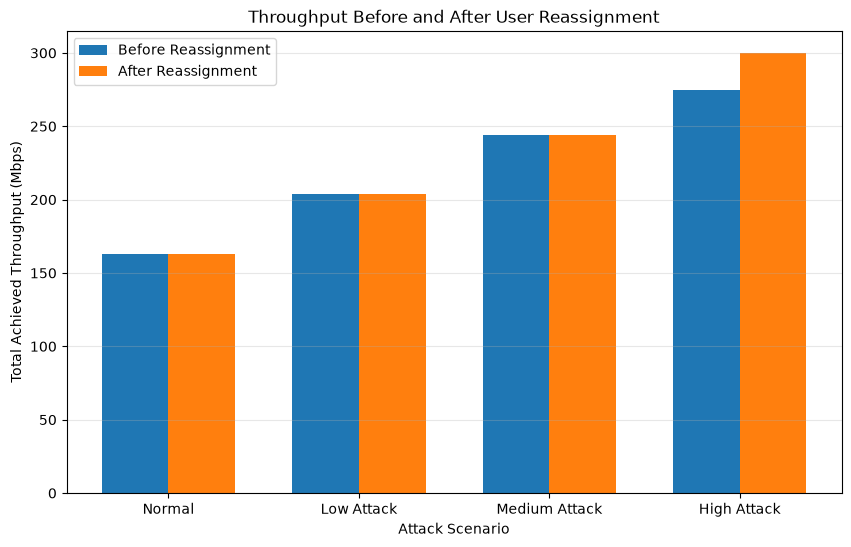

In [ ]:
# STEP 18.7 - Throughput Comparison

throughput_before_values = [
    np.sum(throughput_results[s])
    for s in scenario_names
]

throughput_after_values = [
    np.sum(throughput_after_reassignment[s])
    for s in scenario_names
]

x = np.arange(len(scenario_names))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width/2,
    throughput_before_values,
    width,
    label="Before Reassignment"
)

plt.bar(
    x + width/2,
    throughput_after_values,
    width,
    label="After Reassignment"
)

plt.xticks(
    x,
    scenario_names
)

plt.xlabel("Attack Scenario")
plt.ylabel("Total Achieved Throughput (Mbps)")
plt.title(
    "Throughput Before and After User Reassignment"
)

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.savefig("figures_Throughput_Before_After_18_7.png", dpi=300, bbox_inches="tight")
plt.show()

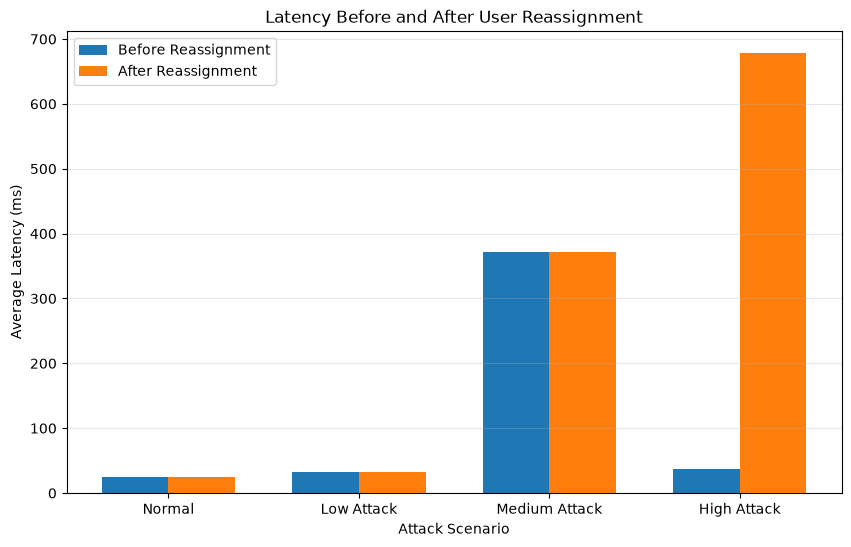

In [ ]:
# STEP 18.8 - Latency Comparison

latency_before_values = [
    np.mean(latency_results[s])
    for s in scenario_names
]

latency_after_values = [
    np.mean(latency_after_reassignment[s])
    for s in scenario_names
]

x = np.arange(len(scenario_names))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width/2,
    latency_before_values,
    width,
    label="Before Reassignment"
)

plt.bar(
    x + width/2,
    latency_after_values,
    width,
    label="After Reassignment"
)

plt.xticks(
    x,
    scenario_names
)

plt.xlabel("Attack Scenario")
plt.ylabel("Average Latency (ms)")
plt.title(
    "Latency Before and After User Reassignment"
)

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.savefig("figures_Latency_Before_After_18_8.png", dpi=300, bbox_inches="tight")
plt.show()

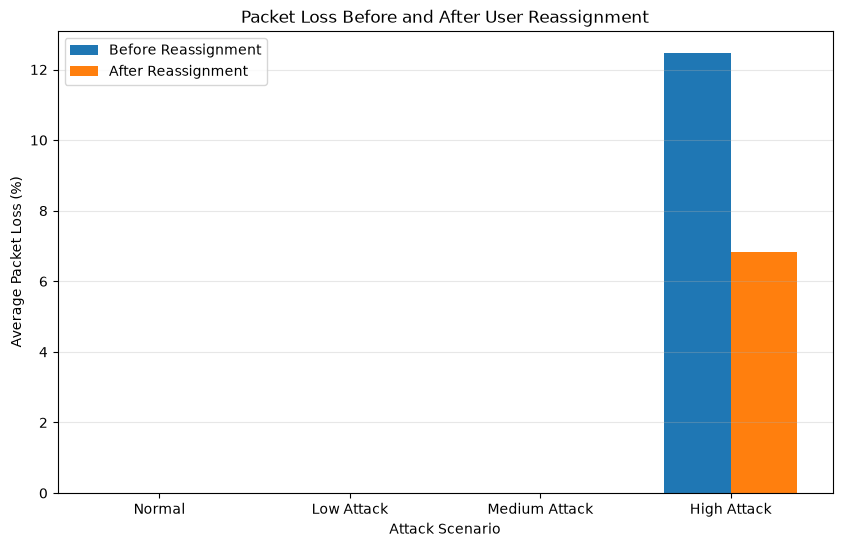

In [ ]:
# STEP 18.9 - Packet Loss Comparison

loss_before_values = [
    np.mean(packet_loss_results[s])
    for s in scenario_names
]

loss_after_values = [
    np.mean(packet_loss_after_reassignment[s])
    for s in scenario_names
]

x = np.arange(len(scenario_names))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width/2,
    loss_before_values,
    width,
    label="Before Reassignment"
)

plt.bar(
    x + width/2,
    loss_after_values,
    width,
    label="After Reassignment"
)

plt.xticks(
    x,
    scenario_names
)

plt.xlabel("Attack Scenario")
plt.ylabel("Average Packet Loss (%)")
plt.title(
    "Packet Loss Before and After User Reassignment"
)

plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.savefig("figures_Packet_Loss_Before_After_18_9.png", dpi=300, bbox_inches="tight")
plt.show()